# 01 — Data overview

A quick look at the three raw datasets (see `data/README.md`):

1. Foursquare POIs — one file per metro area
2. ACS socio-economic indicators — one row per census tract
3. Census tract geometries

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "../data/raw/"

In [2]:
# ── 1. Foursquare POIs ────────────────────────────────────────────────────────
# one parquet file per metro: foursquare_<cbsacode>_<name>_places.parquet
pois = pd.read_parquet(RAW + "POI_US_top50_metros/foursquare_14460_boston_places.parquet")

print(f"Boston POIs: {len(pois)}")
pois[["fsq_place_id", "name", "latitude", "longitude", "fsq_category_labels", "cbsacode"]].head()

Boston POIs: 387309


,fsq_place_id,name,latitude,longitude,fsq_category_labels,cbsacode
0,4eaaed7d775bf08569c33ad9,Aidekman Performance Hanger,42.404425,-71.120613,[Arts and Entertainment > Performing Arts Venue],14460
1,5b099073b77c77002c55bbe1,Ua Flight 3413,42.360584,-71.016869,[Travel and Transportation > Transport Hub > A...,14460
2,2a7e87816c514f056e438cc0,James Harold Traynor CPA,42.971279,-71.185209,[Business and Professional Services > Financia...,14460
3,4ee3ab174690f8893fc67686,Medway Garden Center,42.143886,-71.442333,[Retail > Garden Center],14460
4,4d9b416803d8721ede85e324,Simon Willard Woods,42.468425,-71.370947,[Landmarks and Outdoors > Hiking Trail],14460


In [3]:
# ── 2. ACS indicators (2012–2020) ─────────────────────────────────────────────
# wide format: one column per variable and year, e.g. income2020, population2020
acs = pd.read_csv(RAW + "acs_data_census_tracts_2012_2020.csv.gz")

print(f"Census tracts: {len(acs)}")
acs[["tract_id", "population2020", "income2020", "education_bachelor2020", "education_total2020"]].head()

Census tracts: 38788


,tract_id,population2020,income2020,education_bachelor2020,education_total2020
0,14000US34003001000,NaN,NaN,NaN,NaN
1,14000US34003002100,1459.0,99410.0,484.0,1052.0
2,14000US34003002200,5561.0,51239.0,1556.0,3867.0
3,14000US34003002300,5789.0,54681.0,1280.0,3953.0
4,14000US34003003100,5670.0,34545.0,1401.0,4060.0


Census tracts: 38788


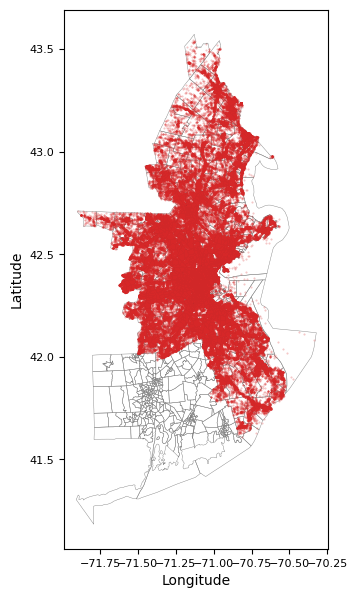

In [4]:
# ── 3. census tract geometries ────────────────────────────────────────────────
# the file has one GeoJSON feature per line, so we read it line by line
with open(RAW + "censustract_geoms_top50.geojson") as f:
    features = [json.loads(line) for line in f]
tracts = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")
print(f"Census tracts: {len(tracts)}")

# ── map: Boston tracts + POIs ───────────────────────────────────────────────
xmin, ymin, xmax, ymax = pois["longitude"].min(), pois["latitude"].min(), pois["longitude"].max(), pois["latitude"].max()
tracts_boston = tracts.cx[xmin:xmax, ymin:ymax]

fig, ax = plt.subplots(figsize=(7, 7))
tracts_boston.plot(ax=ax, facecolor="none", edgecolor="grey", linewidth=0.3)
ax.scatter(pois["longitude"], pois["latitude"], s=0.2, color="tab:red", alpha=0.3)
ax.set_xlabel("Longitude", fontsize=FS)
ax.set_ylabel("Latitude", fontsize=FS)
ax.tick_params(labelsize=FS2)